## Test Grid SANOS



In [ ]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.sanos.utils
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.fitter

from quantdata.dysanos.simple.aec import load_data
data = load_data(["SPX"]).data['SPX']
print(f"/done; columns {data.keys()}")



00: Importing torch...done; this took 0.00453ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 1.6s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 1.7s.
/done; columns dict_keys(['dates', 'ask_pure_delta', 'ask_pure_dk', 'ask_pure_gamma', 'ask_pure_price', 'ask_pure_theta', 'ask_pure_vega', 'ask_vol', 'bid_pure_delta', 'bid_pure_dk', 'bid_pure_gamma', 'bid_pure_price', 'bid_pure_theta', 'bid_pure_vega', 'bid_vol', 'call_ask', 'call_bid', 'df', 'fw

00: SPX 2025-07-01: constructing expanded strike range... done; this took 0.654ms. The following issues were encountered and dealt with:
01:   Downside dC/dK for tte 37.000d is -1.020, which must exceed -1. Skipping this expiry. [tolerance -1.000e-06]


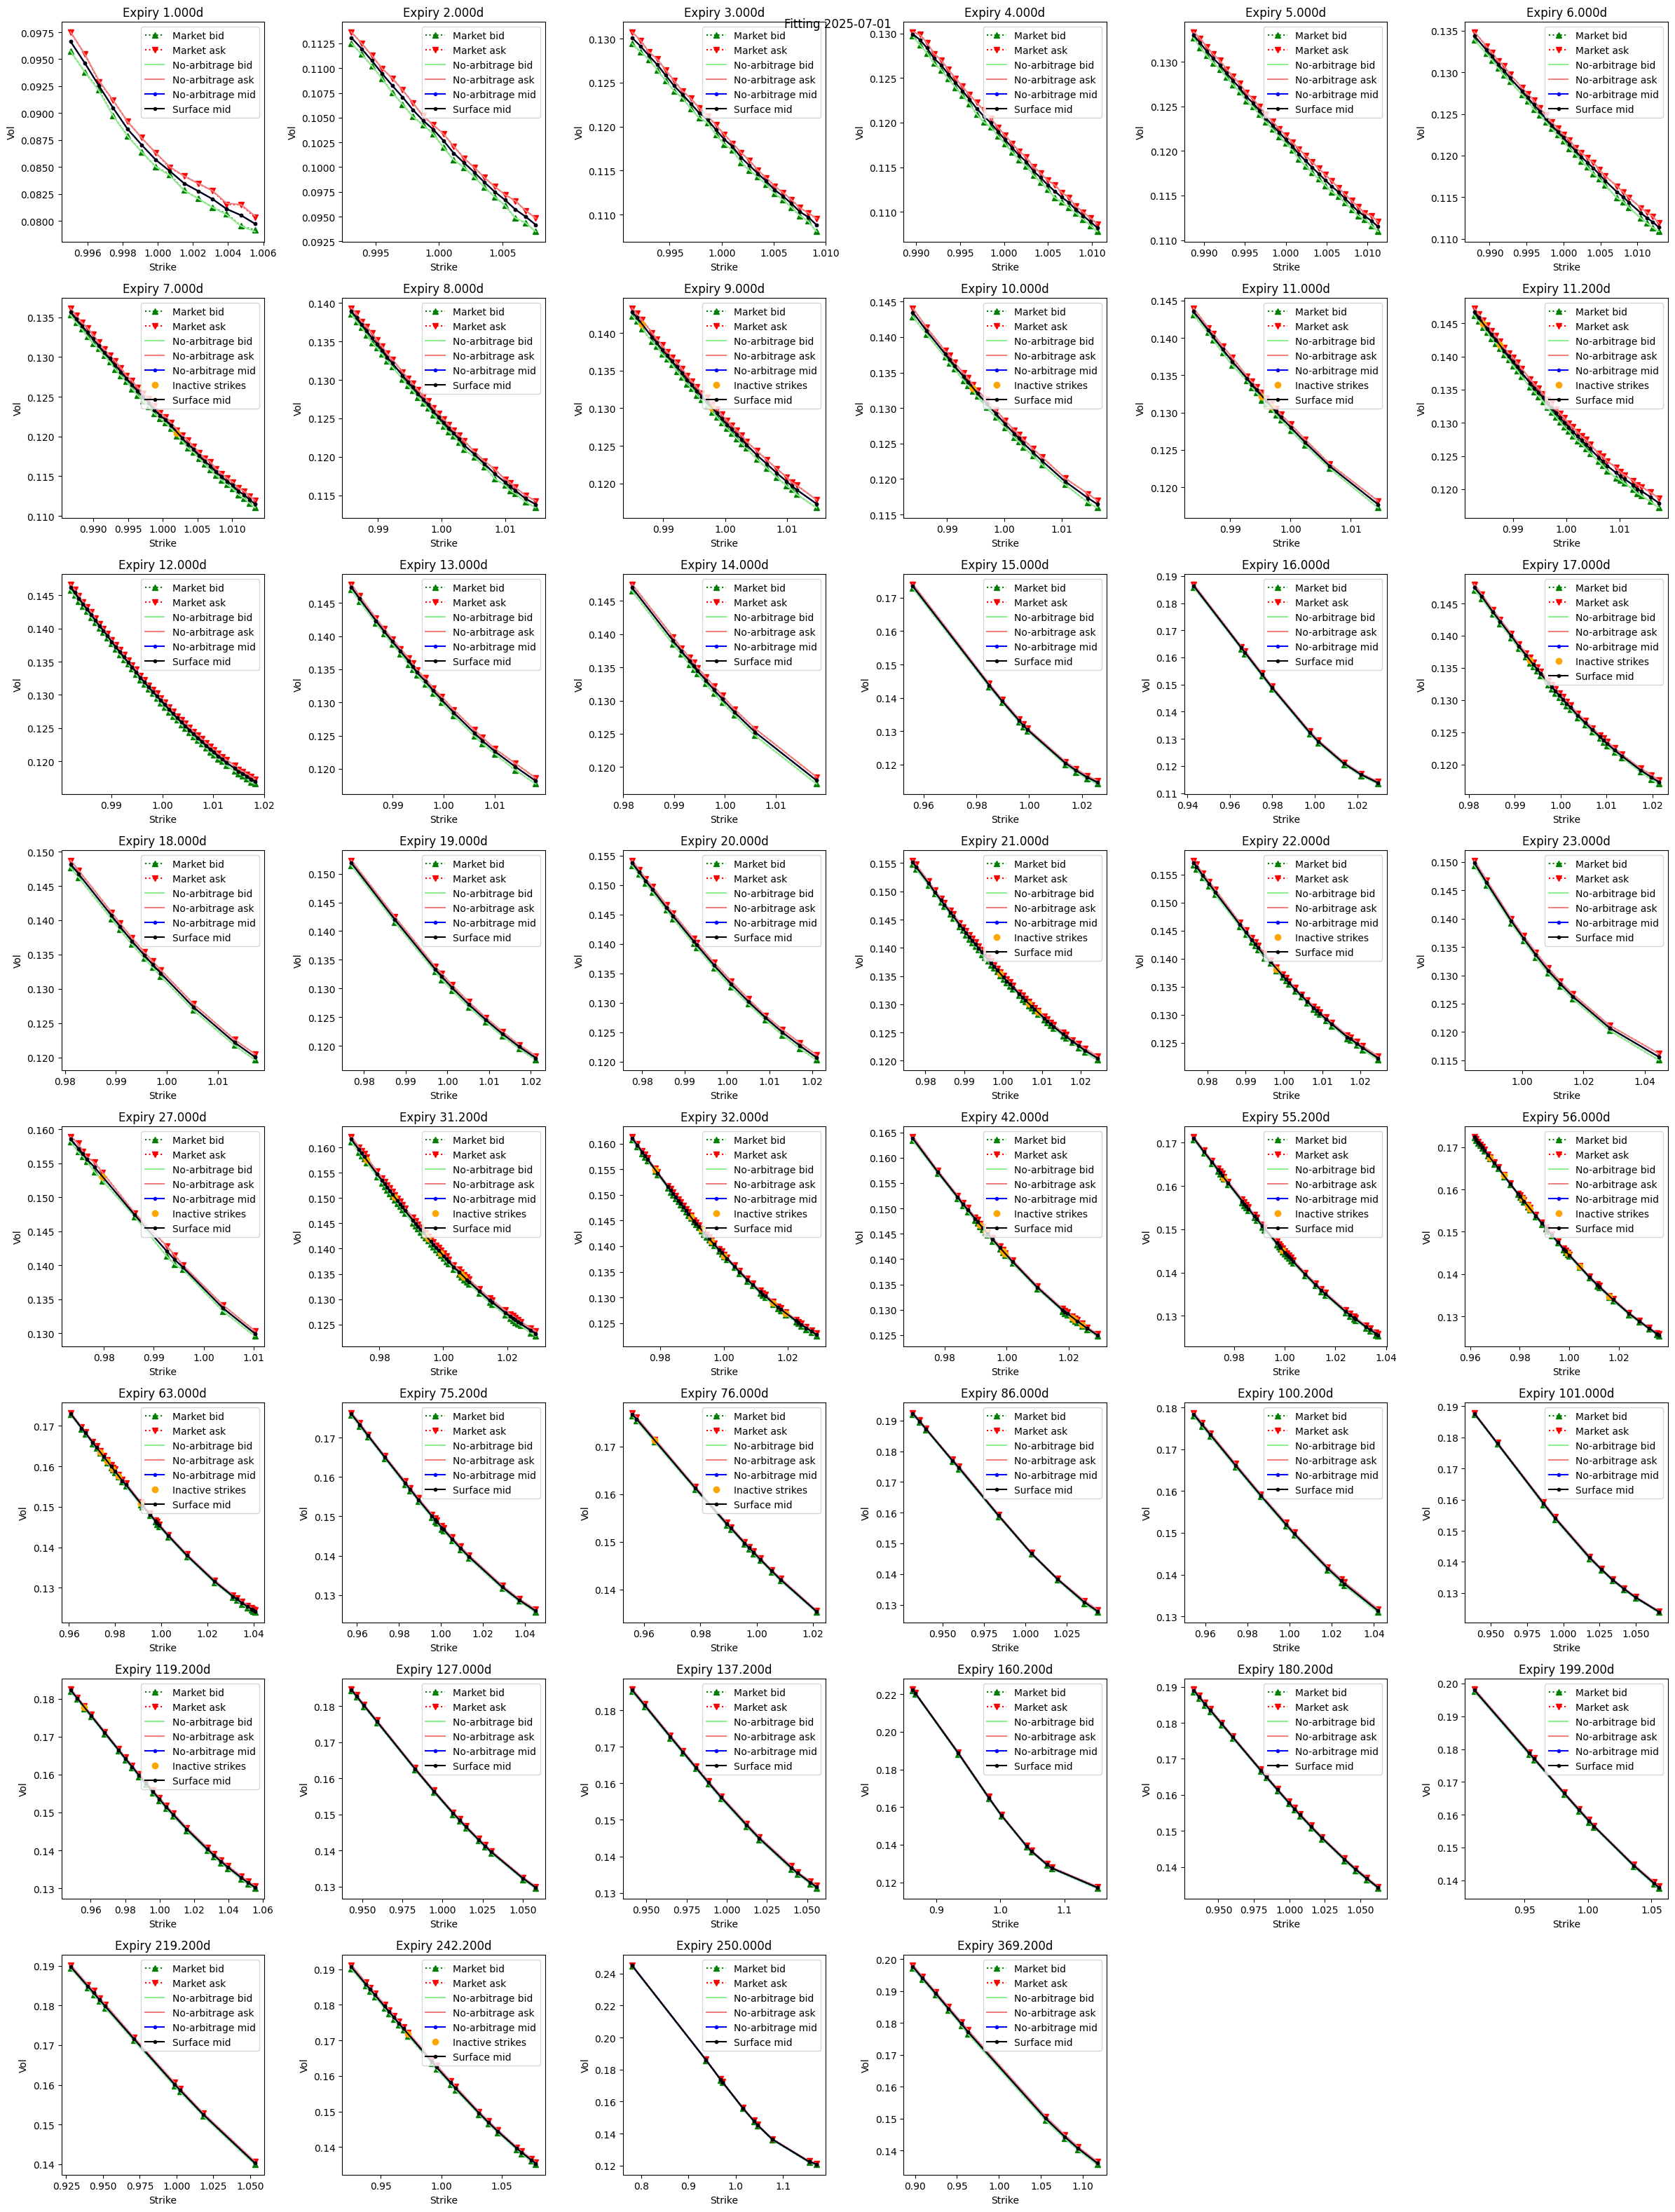

00: SPX 2025-07-01: finding arbitrage-free mids per expriry... done; this took 2s. The following issues were encountered and dealt with:
01:   Found 1/34 inactive strikes with zero point probability for expiry 7.000d. These strikes and their prices will be removed.
01:   Found 2/30 inactive strikes with zero point probability for expiry 9.000d. These strikes and their prices will be removed.
01:   Found 1/20 inactive strikes with zero point probability for expiry 10.000d. These strikes and their prices will be removed.
01:   Found 2/17 inactive strikes with zero point probability for expiry 11.000d. These strikes and their prices will be removed.
01:   Found 2/38 inactive strikes with zero point probability for expiry 11.200d. These strikes and their prices will be removed.
01:   Found 1/29 inactive strikes with zero point probability for expiry 17.000d. These strikes and their prices will be removed.
01:   Found 3/43 inactive strikes with zero point probability for expiry 21.000d. The

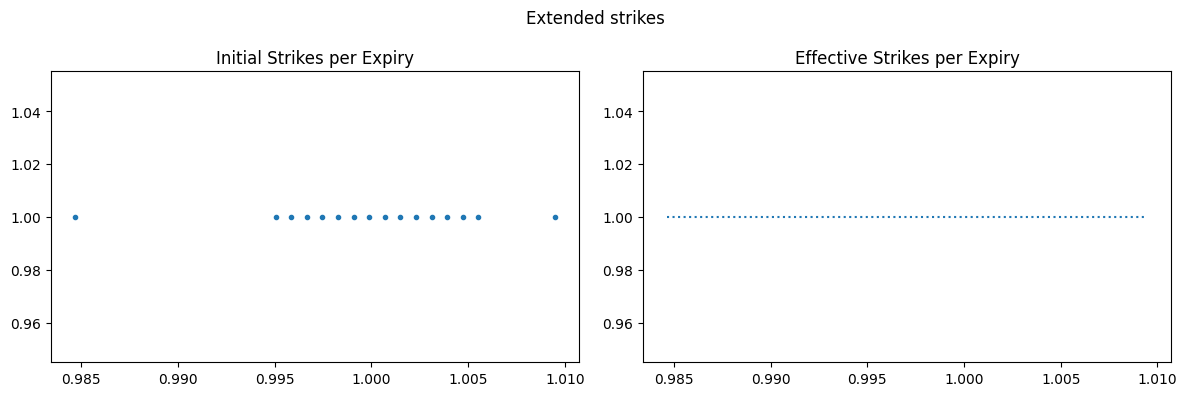

01:   Solving the linear program.. done; this tool 0.73s.


In [15]:
%aimport quantdata.sanos.utils
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.fitter

from dataclasses import dataclass, field
import math

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store, m_o_m
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.sanos.grid import GridGeometry, GridGeometryGenerator, GridSanos, BackboneNumpy
from quantdata.sanos.fitter import Eps, Fitter
import numpy as np
from cdxcore.pretty import PrettyObject
import cvxpy as cp
import warnings

def fit(data):
    num_samples = len(data.dates)

    def fit_sample( ticker, isample, store, verbose : Context = Context.all ):

        d          = data.dates[isample]
        is_valid   = data.is_valid[isample,:]
        strikes    = data.pure_strike[isample,is_valid]
        tte_y      = data.tte_y[isample,is_valid]
        bid_vol    = data.bid_vol[isample,is_valid]
        ask_vol    = data.ask_vol[isample,is_valid]
        bid        = data.bid_pure_price[isample,is_valid]
        ask        = data.ask_pure_price[isample,is_valid]

        # find lowest/highest strike
        # --------------------------
        # -1 >= { C_0 - C_1 }/{ K_0 - K_1} = { 1 - K_0 - C_1 }/{ K_0 - K_1} => K_1 - K_0 >= 1 - K_0 
        
        uttys      = np.unique(tte_y)

        r = PrettyObject()

        @dataclass(frozen=True)
        class ArbFreeConfig:
            min_strikes_per_expiry: int = 5
            min_dC_eps           : float = -1E-6
            cvxpy_solver         : str = "CLARABEL" #:  Solver to use for the convex optimization problem in :meth:`fit_dlvsqs`, c.f. `list of cvxpy solvers <https://www.cvxpy.org/tutorial/solvers/index.html#choosing-a-solver>`_.
            cvxpy_solver_options : dict = field(default_factory=dict) #: Options to pass to the CVXPY solver.
            min_half_spread      : float = 1E-5 #: Maximum weight for tight bid-ask spreads; the optimization problem will weight the errors by the inverse of the spread, but this parameter caps the maximum weight to avoid numerical issues with very tight spreads.
            mid_fit_weight       : float = 0.1 #: Weight for fitting to the mid prices of options. Set to 1. to only fit the mid price.
            min_density          : float = 1E-4 #: Minimum density value to consider in the optimization.
            min_dx : float = 0.00001

        arb_free_config = ArbFreeConfig()

        def collect():
            r = PrettyObject()
            r.expiries   = []
            r.strikes    = []
            r.xstrikes   = []
            r.bid        = []
            r.ask        = []
            r.bid_vol    = []
            r.ask_vol    = []
            min_k        = 1.
            max_k        = 1.
            warn         = []

            with verbose.write_t(lambda: f"{ticker} {d}: constructing expanded strike range... ", end='') as tme:
                for utty in uttys:
                    mask       = tte_y == utty
                    strikes_t  = strikes[mask]
        
                    if len(strikes_t) <= arb_free_config.min_strikes_per_expiry:
                        warn.append( f"Not enough strikes for tte {utty*DAYS_PER_YEAR:.3f}d, skipping")
                        continue

                    ixs        = np.argsort(strikes_t)
                    strikes_t  = strikes_t[ixs]
                    bid_t      = bid[mask][ixs]
                    ask_t      = ask[mask][ixs]

                    # extend strike range
                    # At K_0 and K_n call prices are intrinsic
                    # -1 <= { C_0 - C_1 }/{ K_0 - K_1 } <= dC_1
                    # Assuming -1 < dC_1:
                    # { 1 - K_0 - C_1) <= dC_1 (K_0 - K_1) => 1 - C_1 + K_1 dC_1 <= K_0 (1 + dC_1) => K_0 >= (1 - C_1 + K_1 dC_1)/(1 + dC_1)
                    #
                    # K_N
                    # dC_{N-2} <= { C_{N-1} - C_N }/{ K_{N-1} - K_N } <= 0
                    # Assuming dC_N-1 >= 0 and noting C_N = 0
                    # dC_{N-2} ( K_{N-1} - K_N ) <= C_{N-1} => K_N >= K_{N-1} - C_{N-1}/dC_{N-2}

                    C_1   = ask_t[0]
                    K_1   = strikes_t[0]
                    C_Nm1 = ask_t[-1]
                    K_Nm1 = strikes_t[-1]

                    dC_1 = (C_1 - bid_t[1])/(K_1 - strikes_t[1]) # this must be bigger than -1 (using ask-bid is the steepest inside bid/ask slope)
                    if dC_1 < -1.+arb_free_config.min_dC_eps:
                        warn.append( f"Downside dC/dK for tte {utty*DAYS_PER_YEAR:.3f}d is {dC_1:.3f}, which must exceed -1. Skipping this expiry. [tolerance {arb_free_config.min_dC_eps:.3e}]")
                        continue
                    dC_Nm2 = (C_Nm1 - ask_t[-2])/(K_Nm1 - strikes_t[-2]) # this must be smaller than 0 (using bid-ask is the steepest inside bid/ask slope)
                    if dC_Nm2 >= -arb_free_config.min_dC_eps:
                        warn.append( f"Upside dC/dK for tte {utty*DAYS_PER_YEAR:.3f}d is {dC_Nm2:.3f}, but must be negative. Skipping this expiry [tolerance {arb_free_config.min_dC_eps:.3e}]")
                        continue

                    lower_k = (1 - C_1 + K_1 * dC_1)/(1 + dC_1)
                    upper_k = K_Nm1 - C_Nm1/dC_Nm2
                    assert 0. < lower_k < K_1, f"Internal error: lower_k {lower_k:.3f} is not between 0 and K_1 {K_1:.3f}"
                    assert upper_k > K_Nm1, f"Internal error: upper_k {upper_k:.3f} is not bigger than K_Nm1 {K_Nm1:.3f}"

                    dK0        = K_1 - lower_k
                    lower_k    = max( lower_k/2., K_1 - dK0*2. )
                    dkN        = upper_k - K_Nm1
                    upper_k    = K_Nm1 + dkN*2.
                    xstrikes_t = np.concatenate(([lower_k], strikes_t, [upper_k]))

                    r.expiries.append( utty )
                    r.strikes.append( strikes_t )
                    r.bid.append( bid_t )
                    r.ask.append( ask_t )
                    r.bid_vol.append( bid_vol[mask][ixs] )
                    r.ask_vol.append( ask_vol[mask][ixs] )
                    r.xstrikes.append( xstrikes_t )

                    min_k = min(min_k, lower_k)
                    max_k = max(max_k, upper_k)


                r.expiries = np.array(r.expiries, dtype=np.float32)
                T      = len(r.expiries)

                lower  = np.minimum.accumulate([ r.xstrikes[t][0] for t in range(T) ])
                higher = np.maximum.accumulate([ r.xstrikes[t][-1] for t in range(T) ])

                for t in range(T):
                    xstrikes_t  = r.xstrikes[t]
                    assert xstrikes_t[0] >= lower[t] and xstrikes_t[-1] <= higher[t], f"Internal error: strikes {r.strikes[t][0]:.3f}..{r.strikes[t][-1]:.3f} not within extended strikes {lower[t]:.3f}..{higher[t]:.3f}"
                    xstrikes_t[0] = lower[t]
                    xstrikes_t[-1] = higher[t] 

                if len(warn) > 0 and verbose.shall_report(1):
                    verbose.write(lambda : f"done; this took {tme}. The following issues were encountered and dealt with:", head=False)
                    for w in warn:
                        verbose.report(1,w)
                else:
                    verbose.write(lambda : f"done; this took {tme}.", head=False)
            
            return r

        r = collect()

        with figure(f"Fitting {d}", row_size=4, col_size=4, columns=6) as fig:#
            axs = []
            for tte in r.expiries:
                ax = fig.add_subplot( f"Expiry {tte*DAYS_PER_YEAR:.3f}d" )
                ax.set_xlabel("Strike")
                ax.set_ylabel("Vol")
                axs.append( ax )    
            store = fig.store()
            fig.render()

            # solve problem independently for each expiry

            def solve_singles(r):
                af = PrettyObject()
                af.expiries = []
                af.xstrikes = []
                af.bid = []
                af.ask = []
                af.bid_vol = []
                af.ask_vol = []
                af.density = []

                T = len(r.expiries)
                warn = []

                with verbose.write_t(lambda: f"{ticker} {d}: finding arbitrage-free mids per expriry... ", end='') as tme:
                    for t in  range(T):
                        tte         = r.expiries[t]
                        xstrikes_t  = r.xstrikes[t]
                        strikes_t   = xstrikes_t[1:-1]
                        Nt          = len(strikes_t)
                        C           = cp.Variable(Nt+2, nonneg=True)
                        dC          = cp.multiply( C[1:] - C[:-1], 1./( xstrikes_t[1:] - xstrikes_t[:-1] ) )
                        constraints = [ -1 <= dC[0],
                                        dC[:-1] <= dC[1:],
                                        dC[-1] <= 0 ,
                                        C[1:-1] <= r.ask[t],
                                        C[1:-1] >= r.bid[t] ]
                        half_spread = np.maximum( (r.ask[t] - r.bid[t])/2., arb_free_config.min_half_spread )
                        mid         = (r.bid[t] + r.ask[t])/2.
                        inv_half    = 1./half_spread
                        objective   = cp.sum( cp.multiply( inv_half, C[1:-1] - mid )**2 )

                        prob        = cp.Problem( cp.Minimize( objective ), constraints )
                        prob.solve( solver=arb_free_config.cvxpy_solver, **arb_free_config.cvxpy_solver_options )

                        if prob.status != "optimal":
                            if prob.status == "infeasible":
                                warn.append( f"Cannot find linear no-arbitrage mid for expory {tte*DAYS_PER_YEAR:4f}d (infeasible problem) -- removing expiry.")
                                continue
                            warn.append( f"Optimization problem for tte {tte*DAYS_PER_YEAR:.3f}d returned '{prob.status}' -- proceeding anyway." )

                        # flag options which do not seem to have any
                        # density (e.g. where calls are linear) as inactive.
                        C         = C.value
                        dC        = np.diff( C, prepend=1. ) / np.diff(xstrikes_t, prepend=0.)
                        p         = np.diff( dC, prepend=-1. ) / np.diff(xstrikes_t, prepend=0.)
                        active    = p > ( arb_free_config.min_density / float(Nt) )
                        active[0] = True
                        active[-1] = True
                        active    = active if not np.all(active) else None

                        if not active is None:
                            warn.append( f"Found {Nt+2-np.sum(active)}/{Nt} inactive strikes with zero point probability for expiry {tte*DAYS_PER_YEAR:.3f}d. These strikes and their prices will be removed.")

                        # compute new bid-ask.
                        af_xstrikes = xstrikes_t
                        af_ask      = C[1:-1] + half_spread
                        af_bid      = C[1:-1] - half_spread
                        af_mid      = C[1:-1]
                        af_density  = p

                        bad_strikes = None
                        bad_mid_vol = None

                        if not active is None:
                            af_xstrikes = xstrikes_t[active]
                            af_ask     = af_ask[active[1:-1]]
                            af_bid     = af_bid[active[1:-1]]
                            af_mid     = af_mid[active[1:-1]]
                            af_density = af_density[active]
                            bad_strikes = xstrikes_t[~active]
                            bad_mid_vol = ( r.bid_vol[t][~active[1:-1]] + r.ask_vol[t][~active[1:-1]] )/2.
                        del active

                        af_ask_vol = bs.implied( af_xstrikes[1:-1], af_ask, sqrtT=math.sqrt(tte) )
                        af_bid_vol = bs.implied( af_xstrikes[1:-1], af_bid, sqrtT=math.sqrt(tte) )
                        af_mid_vol = bs.implied( af_xstrikes[1:-1], af_mid, sqrtT=math.sqrt(tte) )

                        af.expiries.append( tte )
                        af.xstrikes.append( af_xstrikes )
                        af.bid.append( af_bid )
                        af.ask.append( af_ask )
                        af.bid_vol.append( af_bid_vol )
                        af.ask_vol.append( af_ask_vol )
                        af.density.append( af_density )

                        af_density = p 

                        ax = axs[t]
                        ax.plot( r.xstrikes[t][1:-1], r.bid_vol[t], "^:", color="green", label="Market bid")
                        ax.plot( r.xstrikes[t][1:-1], r.ask_vol[t], "v:", color="red", label="Market ask")
                        ax.plot( af_xstrikes[1:-1], af_bid_vol, "-", color="lightgreen", label="No-arbitrage bid")
                        ax.plot( af_xstrikes[1:-1], af_ask_vol, "-", color="lightcoral", label="No-arbitrage ask")
                        ax.plot( af_xstrikes[1:-1], af_mid_vol, ".-", color="blue", label="No-arbitrage mid" )
                        if not bad_strikes is None:
                            ax.plot( bad_strikes, bad_mid_vol, "o", color="orange", label="Inactive strikes" )
                        ax.legend(loc="upper right")
                        ax.set_ylim( m_o_m( r.bid_vol[t], r.ask_vol[t], af_bid_vol, af_ask_vol ) )

                    af.expiries = np.array(af.expiries, dtype=np.float32)
                    fig.render()
                    if len(warn) > 0 and verbose.shall_report(1):
                        verbose.write(lambda : f"done; this took {tme}. The following issues were encountered and dealt with:", head=False)
                        for w in warn:
                            verbose.report(1,w)
                    else:
                        verbose.write(lambda : f"done; this took {tme}.", head=False)
                return af
            
            af = solve_singles(r)
            del r

            # full surface arb fit
            # --------------------

            def solve_surface(af):
                T           = len(af.expiries)

                sf = PrettyObject()
                sf.expiries = af.expiries
                sf.mstrikes = [None]*T  # model strikes, extended
                sf.strikes  = [ xk_t[1:-1] for xk_t in af.xstrikes ] # market strikes, without extended strikes
                sf.bid      = af.bid
                sf.ask      = af.ask
                sf.bid_vol  = af.bid_vol
                sf.ask_vol  = af.ask_vol

                verbose.write(lambda: f"{ticker} {d}: finding arbitrage-free mids accross the surface: ")
                alltme = verbose.timer()
                verbose1 = verbose(1)
                # generate extended expiries
                # --------------------------

                with figure("Extended strikes", row_size=4, col_size=6, columns=2) as figK:
                    axIn, axOut = figK.add_subplots("Initial Strikes per Expiry", "Effective Strikes per Expiry")

                    with verbose1.write_t("Constructing extended strike grid.. ", end='') as tme:
                        for t in range(T-1,-1,-1):
                            # fix strikes
                            # 1) Ensure outside strike range is increasing.
                            # 2) Add strikes of next expiry if not too close to existing strikes. Always keep current strikes
                            xstrikes_t = af.xstrikes[t]
                            mstrikes_t = xstrikes_t
                            if t<T-1:
                                next_mstrikes = sf.mstrikes[t+1]
                                assert next_mstrikes[0] <= xstrikes_t[0] and next_mstrikes[-1] >= xstrikes_t[-1], f"Internal error: next_mstrikes[0] {next_mstrikes[0]:.3f} > xstrikes_t[0] {xstrikes_t[0]:.3f} or next_mstrikes[-1] {next_mstrikes[-1]:.3f} < xstrikes_t[-1] {xstrikes_t[-1]:.3f}"

                                min_dx   = min( np.diff(mstrikes_t).min(), np.diff(next_mstrikes).min() )
                                collect  = []
                                inext    = 0
                                add_any  = False

                                # skip next strikes until relevant
                                while next_mstrikes[inext] <= xstrikes_t[0]+min_dx:
                                    inext += 1

                                collect = [ xstrikes_t[0] ]

                                for ithis in range(1, xstrikes_t.shape[0]):
                                    k = xstrikes_t[ithis]
                                    # add next strikes up to 'k'
                                    while next_mstrikes[inext] <= k-min_dx:
                                        collect.append( next_mstrikes[inext] )
                                        add_any = True
                                        inext += 1
                                    collect.append( k )
                                    # skip next_mstrikes which are too close to k
                                    while next_mstrikes[inext] <= k+min_dx:
                                        inext += 1
                                        if inext >= next_mstrikes.shape[0]:
                                            break

                                if add_any:
                                    mstrikes_t = np.array(collect, dtype=xstrikes_t.dtype)
                                    assert np.min( np.diff( mstrikes_t ) ) >= arb_free_config.min_dx, f"Internal error: min dx {np.diff(mstrikes_t).min():.3f} < min_dx {arb_free_config.min_dx:.3f}"
                                    assert mstrikes_t[0] == xstrikes_t[0] and mstrikes_t[-1] == xstrikes_t[-1], f"Internal error: mstrikes_t[0] {mstrikes_t[0]:.3f} != xstrikes_t[0] {xstrikes_t[0]:.3f} or mstrikes_t[-1] {mstrikes_t[-1]:.3f} != xstrikes_t[-1] {xstrikes_t[-1]:.3f}"

                            sf.mstrikes[t] = mstrikes_t
                            tte_d = af.expiries[t]*DAYS_PER_YEAR

                        verbose1.write(lambda : f"done; this took {tme}.", head=False)
                        axOut.plot( mstrikes_t, mstrikes_t*0.+tte_d, ":", label=f"Exp {tte_d:.3f}d #{len(xstrikes_t)}/{len(mstrikes_t)}" )
                        axIn.plot( xstrikes_t, xstrikes_t*0.+tte_d, ".")
                    del af

                # DLV
                # ---

                densities   = []
                fit_mids    = []
                constraints = []
                objective   = 0.
                warn        = []

                with verbose1.write_t("Solving the linear program.. ", end='') as tme:
                    for t in range(T):
                        mstrikes_t  = sf.mstrikes[t]
                        strikes_t   = sf.strikes[t]
                        ask_t       = sf.ask[t]
                        bid_t       = sf.bid[t]

                        q_t         = cp.Variable(len(mstrikes_t), nonneg=True)
                        fit_mid     = cp.maximum( 0., mstrikes_t[None,:] - strikes_t[:,None] ) @ q_t     # market strikes
                        Cm          = cp.maximum( 0., mstrikes_t[None,:] - mstrikes_t[1:-1,None] ) @ q_t    # model strikes

                        if t>0:
                            Cm1     = cp.maximum( 0., sf.mstrikes[t-1][None,:] - mstrikes_t[1:-1,None] ) @ densities[t-1]
                        else:
                            Cm1     = np.maximum( 0., 1 - mstrikes_t[1:-1] )

                        constraints += [ cp.sum( q_t ) == 1.,
                                        q_t @ mstrikes_t == 1., # martingale condition
                                        Cm >= Cm1 ]

                        half_spread = np.maximum( (ask_t - bid_t)/2., arb_free_config.min_half_spread )
                        mid         = (bid_t + ask_t)/2.
                        inv_half    = 1./half_spread
                        excess      = cp.multiply( inv_half, ( cp.maximum( 0., fit_mid - ask_t ) + cp.maximum( 0., bid_t - fit_mid ) ) )
                        objective   = objective + cp.sum( arb_free_config.mid_fit_weight*cp.multiply( inv_half, fit_mid - mid )**2 + (1.-arb_free_config.mid_fit_weight) * excess )

                        fit_mids.append(fit_mid)
                        densities.append(q_t)

                    prob        = cp.Problem( cp.Minimize( objective ), constraints )
                    prob.solve( solver=arb_free_config.cvxpy_solver, **arb_free_config.cvxpy_solver_options )

                    if prob.status != "optimal":
                        if prob.status == "infeasible":
                            raise RuntimeError(f"Cannot find no-arbitrage surface mids: problem infeasible??")
                        verbose1.write(lambda : f"solver returned '{prob.status}' -- proceeding anyway... ", head=False, end='' )

                    for t in range(T):
                        # flag options which do not seem to have any
                        # density (e.g. where calls are linear) as inactive.
                        fit_mid      = fit_mids[t].value
                        half_spread  = np.maximum( (sf.ask[t] - sf.bid[t])/2., arb_free_config.min_half_spread )
                        strikes_t    = sf.strikes[t]
                        tte          = sf.expiries[t]

                        # compute new bid-ask.
                        sf_ask       = fit_mid + half_spread
                        sf_bid       = fit_mid - half_spread
                        sf_ask_vol   = bs.implied( strikes_t, sf_ask, sqrtT=math.sqrt(tte) )
                        sf_bid_vol   = bs.implied( strikes_t, sf_bid, sqrtT=math.sqrt(tte) )
                        sf_mid_vol   = bs.implied( strikes_t, fit_mid, sqrtT=math.sqrt(tte) )
                        sf.bid.append( sf_bid )
                        sf.ask.append( sf_ask )
                        sf.bid_vol.append( sf_bid_vol )
                        sf.ask_vol.append( sf_ask_vol )

                        ax = axs[t]
                        ax.plot( strikes_t, sf_mid_vol, ".-", color="black", label="Surface mid" )
                        ax.legend(loc="upper right")

                    verbose1.write(lambda : f"done; this tool {tme}.", head=False )
                    return sf

            sf = solve_surface(af)


    ticker = "SPX"
    for isample in range(num_samples-1,num_samples-200,-20):
        fit_sample(ticker, isample, store)
        break

fit(data)
